# Code notebook by Dominic Hildebrand, last edited July 2025
Student WUR and whatnot.

In [39]:
majors <- read.csv("C:/Users/domin/Documents/WUR/Thesis/raw_data/majors16_chrats.csv")
minors <- read.csv("C:/Users/domin/Documents/WUR/Thesis/raw_data/minors16_chrats.csv")
thiols <- read.csv("C:/Users/domin/Documents/WUR/Thesis/raw_data/thiols16_chrats.csv")



In [40]:
vine1_majors <- subset(majors, grepl("01[abc]|wgt1", Compound_mg))
head(vine1_majors)

,Compound_mg,Acetaldehyde,Diacetyl,Acetoine,Ethyl.acetate,Isoamyl.acetate,Hexyl.acetate,Ethyl.propanoate,Ethyl.butyrate,Ethyl.hexanoate,⋯,Ethyl.lactate,Diethyl.succinate,X..Butyrolactone,Acetic.acid,Butyric.acid,Isobutyric.acid,Isovalerianic.acid,Hexanoic.acid,Octanoic.acid,Decanoic.acid
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,01a,0.1394494,0,1.135854,24.78077,0.4582372,0.1253383,0,0.08888060,0.6521310,⋯,4.228617,0.4942664,4.296391,210.3027,0.7388118,0.4692958,0.3813755,4.060917,12.23548,2.232045
2,01b,0.0000000,0,1.283493,30.29664,0.5484220,0.1211709,0,0.09614504,0.6897339,⋯,4.709255,0.4984936,4.282133,297.9943,0.7479703,0.5119262,0.3591870,3.717171,11.55949,2.809959
3,01c,0.0000000,0,1.206777,26.43613,0.4644075,0.1184277,0,0.09213346,0.6225271,⋯,4.459278,0.4935447,4.191281,301.2947,0.6304732,0.5412049,0.3673075,3.327729,10.31549,2.556211
21,wgt1,0.0000000,0,7.519836,84.31924,1.4582323,0.3522897,0,0.16328662,0.0000000,⋯,20.528644,2.1406291,3.440918,431.7801,1.3875078,0.6882448,0.2133756,6.109781,14.85476,2.048828


In [41]:
majors_ <- majors
minors_ <- minors
thiols_ <- thiols
names(majors_)[1] <- "sample_names"
names(minors_)[1] <- "sample_names"
names(thiols_)[1] <- "sample_names"

In [42]:
# Merge dataframes
df_list <- list(majors_, minors_, thiols_)

#merge all data frames in list
merged <- Reduce(function(x, y) merge(x, y, all = TRUE), df_list)

In [43]:
merged_df <- data.frame(merged[, -1], row.names = merged[, 1])
head(merged_df)


,Acetaldehyde,Diacetyl,Acetoine,Ethyl.acetate,Isoamyl.acetate,Hexyl.acetate,Ethyl.propanoate,Ethyl.butyrate,Ethyl.hexanoate,Ethyl.octanoate,⋯,Methyl.vanillinate,Ethyl.vanillate,Acetovanillone,Siringaldehyde,MF,FFT,MP,AMH,MOH,BM
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01a,0.1394494,0,1.135854,24.7807685,0.4582372,0.1253383,0,0.08888060,0.6521310,1.0467820,⋯,65.03079,0.4656491,25.05747,0,352.2,3.6,5.6,0.0,156.3,4.9
01b,0.0000000,0,1.283493,30.2966402,0.5484220,0.1211709,0,0.09614504,0.6897339,0.8522695,⋯,69.51278,0.4741759,27.67509,0,679.2,4.3,0.0,357.9,70.3,6.4
01c,0.0000000,0,1.206777,26.4361259,0.4644075,0.1184277,0,0.09213346,0.6225271,0.7892849,⋯,53.32440,0.5122139,21.38606,0,583.3,4.6,0.0,286.1,77.1,5.0
02a,0.0000000,0,3.153335,30.5232888,0.9849052,0.1937636,0,0.19969457,0.8259451,1.0588757,⋯,71.15844,0.6774063,29.92889,0,327.9,2.4,2.9,4.1,123.2,4.9
02b,0.5259511,0,3.094063,31.0149589,1.1803101,0.2523563,0,0.11781310,0.0000000,1.1948172,⋯,62.75946,0.7134218,26.80325,0,543.7,3.2,3.5,75.1,111.5,6.8
02c,0.2427734,0,2.841151,0.2926099,1.1970245,0.2224277,0,0.20886183,0.9494682,1.1943489,⋯,78.13626,0.7465695,31.56124,0,316.9,3.7,4.4,3.8,118.0,4.6


# Here we scale the data
Though not needed. Following gives same result scaled and unscaled.

In [44]:
library(cluster)
library(dplyr)

In [45]:
# install.packages("ggcorrplot")
# library(ggcorrplot)

# ggcorrplot(cor(na.omit(df2)))

Attempt scaling...


In [46]:
merged_scaled_df <- scale(merged_df)


In [47]:
# So this should be uncommented if you want to see the absolute differences in the table at the end.
# Yes, I agree, it's kinda scuffed. But this was rushed...
# And yes, when ever are things not rushed -_-

merged_df <- data.frame(merged_scaled_df [ , colSums(is.na(merged_scaled_df))==0])

# Some quick final analysis AI code... 
I am not proud of it but it's fast. It's dirty and works good enough. 
At least I don't connect the code base to AI but know what I want 
and can fix the broken AI code if need be. 

That's the advantage of having learnt how to program / code before AI, I guess.

In [48]:
# Calculate variance for each column in merged_df
variances <- apply(merged_df, 2, var)

# Sort variances in decreasing order and get column names
sorted_col_names <- names(sort(variances, decreasing = TRUE))

# Show the column names with the largest variation first
variances > 1

Acetaldehyde                    Diacetyl 
                       TRUE                       FALSE 
                   Acetoine               Ethyl.acetate 
                      FALSE                       FALSE 
            Isoamyl.acetate               Hexyl.acetate 
                      FALSE                       FALSE 
             Ethyl.butyrate             Ethyl.hexanoate 
                      FALSE                       FALSE 
            Ethyl.octanoate             Ethyl.decanoate 
                       TRUE                       FALSE 
                 Isobutanol                  X1.Butanol 
                      FALSE                        TRUE 
            Isoamyl.alcohol                  X1.Hexanol 
                      FALSE                       FALSE 
                c.3.Hexenol                    Metionol 
                      FALSE                       FALSE 
           Benzylic.alcohol            X..Phenylethanol 
                      FALSE                       FALSE 
              Ethyl.lactate           Diethyl.succinate 
                      FALSE                       FALSE 
           X..Butyrolactone                 Acetic.acid 
                      FALSE                       FALSE 
               Butyric.acid             Isobutyric.acid 
                      FALSE                       FALSE 
         Isovalerianic.acid               Hexanoic.acid 
                      FALSE                        TRUE 
              Octanoic.acid               Decanoic.acid 
                       TRUE                        TRUE 
          Ethyl.isobutyrate      Ethyl.2.methylbutyrate 
                      FALSE                       FALSE 
          Ethyl.isovalerate            Isobutyl.acetate 
                      FALSE                       FALSE 
              Butyl.acetate         Phenylethyl.acetate 
                      FALSE                       FALSE 
               Benzaldehyde                    Linalool 
                      FALSE                       FALSE 
           Linalool.acetate                X..Terpineol 
                      FALSE                        TRUE 
              X..Citronelol                    Geraniol 
                      FALSE                       FALSE 
             X..Damascenone                   X..Ionone 
                      FALSE                       FALSE 
                   Guaiacol                    o.Cresol 
                      FALSE                       FALSE 
           X4.Ethylguaiacol                    m.Cresol 
                      FALSE                       FALSE 
                    Eugenol              X4.Ethylphenol 
                      FALSE                        TRUE 
           X4.Vinylguaiacol                E.Isoeugenol 
                      FALSE                       FALSE 
       X2.6.Dimethoxyphenol              X4.Vinylphenol 
                      FALSE                       FALSE 
X4.Alyl.2.6.dimethoxyphenol      Ethyl.dihidrocinnamate 
                      FALSE                        TRUE 
            Ethyl.cinnamate             t.Whiskylactone 
                      FALSE                       FALSE 
            c.Whiskylactone              X..Nonalactone 
                      FALSE                       FALSE 
             X..Decalactone                    Vanillin 
                      FALSE                        TRUE 
         Methyl.vanillinate             Ethyl.vanillate 
                      FALSE                       FALSE 
             Acetovanillone                          MF 
                       TRUE                       FALSE 
                        FFT                          MP 
                      FALSE                        TRUE 
                        AMH                         MOH 
                      FALSE                       FALSE 
                         BM 
                       TRUE

In [49]:
# # Calculate variance of each numeric column in merged_df
# variances <- sapply(merged_df, var)

# # Subset the dataframe to keep columns with variance > 1
# filtered_df <- merged_df[, variances > 1000]

# # View the filtered dataframe with columns of variance greater than 1
# boxplot(filtered_df)

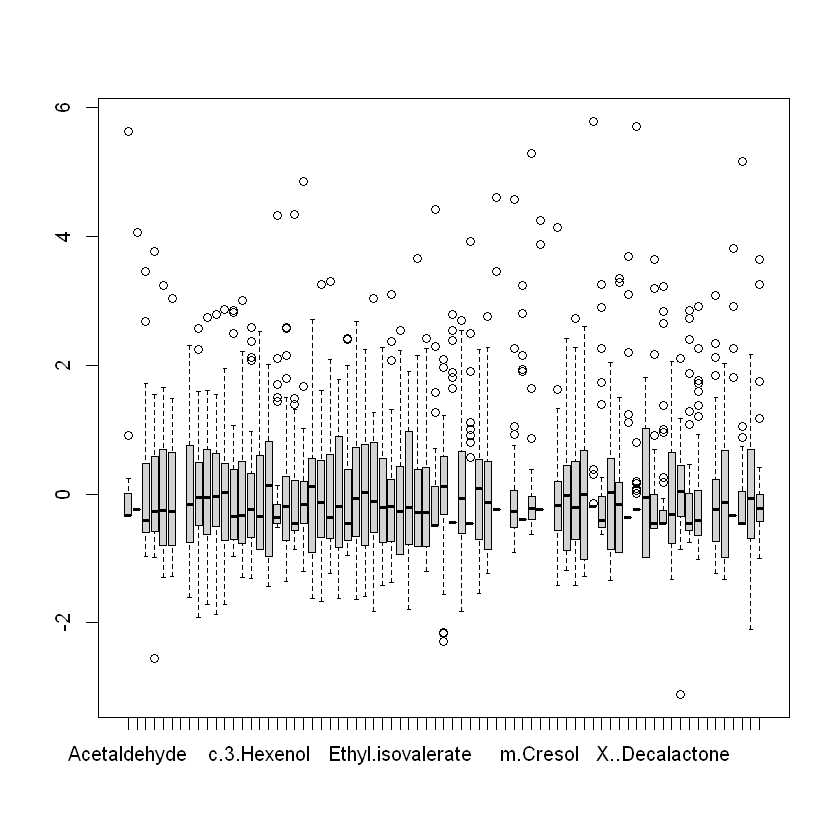

In [50]:
boxplot(merged_scaled_df)

In [51]:
row.names(merged_df)

[1] "01a"      "01b"      "01c"      "02a"      "02b"      "02c"     
 [7] "03a"      "03b"      "03c"      "04a"      "04b"      "04c"     
[13] "05a"      "05b"      "05c"      "06a"      "06c"      "07a"     
[19] "07b"      "07c"      "15a"      "15b"      "15c"      "17a"     
[25] "17b"      "18a"      "18b"      "wgt1"     "wgt2"     "wgt4"    
[31] "wgt5"     "wgt6F77"  "wgt6F775" "wgt6T202" "wgt7F30"  "wgt7T209"

# TEST TEST TEST
Only to see if majors differ much, as 1 mg is 1000 ug, 1 ug is 1000 ng...
Difference in scale is massive, bias!

In [52]:
# merged_df <- data.frame(majors_[, -1], row.names = majors_[, 1])
# merged_df

In [53]:
# Example patterns:
# DF1: rownames start with two digits, a space, then [abc]
pattern_df1 <- "^\\d{2}[abc]"
# DF2: rownames start with 'wgt' followed by one or more digits
pattern_df2 <- "^wgt\\d+"

# Subset for DF1
DF1 <- merged_df[grep(pattern_df1, rownames(merged_df)), ]

# Subset for DF2
DF2 <- merged_df[grep(pattern_df2, rownames(merged_df)), ]


In [54]:
colMeans(DF1)


Acetaldehyde                    Diacetyl 
                0.089054273                -0.079714450 
                   Acetoine               Ethyl.acetate 
               -0.081158339                -0.211836109 
            Isoamyl.acetate               Hexyl.acetate 
               -0.266712553                -0.143959287 
             Ethyl.butyrate             Ethyl.hexanoate 
               -0.231679998                 0.027659712 
            Ethyl.octanoate             Ethyl.decanoate 
                0.079636319                 0.145259184 
                 Isobutanol                  X1.Butanol 
               -0.022934169                -0.070519400 
            Isoamyl.alcohol                  X1.Hexanol 
               -0.137764633                -0.059915772 
                c.3.Hexenol                    Metionol 
               -0.440451435                 0.041160092 
           Benzylic.alcohol            X..Phenylethanol 
               -0.392828857                 0.071496464 
              Ethyl.lactate           Diethyl.succinate 
               -0.228981822                -0.165813111 
           X..Butyrolactone                 Acetic.acid 
               -0.130669583                -0.048307483 
               Butyric.acid             Isobutyric.acid 
               -0.311849214                -0.080407105 
         Isovalerianic.acid               Hexanoic.acid 
               -0.069521745                -0.271561397 
              Octanoic.acid               Decanoic.acid 
               -0.187009731                 0.019497827 
          Ethyl.isobutyrate      Ethyl.2.methylbutyrate 
                0.083983706                 0.035787716 
          Ethyl.isovalerate            Isobutyl.acetate 
               -0.052669626                -0.141727701 
              Butyl.acetate         Phenylethyl.acetate 
               -0.199480769                -0.099293844 
               Benzaldehyde                    Linalool 
               -0.236437829                -0.202023590 
           Linalool.acetate                X..Terpineol 
               -0.084500520                 0.018500177 
              X..Citronelol                    Geraniol 
               -0.157811869                -0.248664180 
             X..Damascenone                   X..Ionone 
               -0.288684668                 0.078951608 
                   Guaiacol                    o.Cresol 
               -0.366717413                -0.388159705 
           X4.Ethylguaiacol                    m.Cresol 
               -0.269550380                 0.079631039 
                    Eugenol              X4.Ethylphenol 
               -0.383352011                -0.227864893 
           X4.Vinylguaiacol                E.Isoeugenol 
               -0.309585405                -0.225319683 
       X2.6.Dimethoxyphenol              X4.Vinylphenol 
               -0.177141546                -0.194805958 
X4.Alyl.2.6.dimethoxyphenol      Ethyl.dihidrocinnamate 
               -0.391970237                 0.004194239 
            Ethyl.cinnamate             t.Whiskylactone 
               -0.156837703                 0.065817647 
            c.Whiskylactone              X..Nonalactone 
               -0.009111497                -0.320003702 
             X..Decalactone                    Vanillin 
               -0.046951465                -0.277822261 
         Methyl.vanillinate             Ethyl.vanillate 
               -0.166517771                -0.479703940 
             Acetovanillone                          MF 
               -0.496098513                -0.341534903 
                        FFT                          MP 
                0.169364375                 0.112375977 
                        AMH                         MOH 
               -0.112400000                 0.132421577 
                         BM 
                0.021365336

In [55]:
colMeans(DF2)

Acetaldehyde                    Diacetyl 
                -0.26716282                  0.23914335 
                   Acetoine               Ethyl.acetate 
                 0.24347502                  0.63550833 
            Isoamyl.acetate               Hexyl.acetate 
                 0.80013766                  0.43187786 
             Ethyl.butyrate             Ethyl.hexanoate 
                 0.69503999                 -0.08297914 
            Ethyl.octanoate             Ethyl.decanoate 
                -0.23890896                 -0.43577755 
                 Isobutanol                  X1.Butanol 
                 0.06880251                  0.21155820 
            Isoamyl.alcohol                  X1.Hexanol 
                 0.41329390                  0.17974732 
                c.3.Hexenol                    Metionol 
                 1.32135430                 -0.12348028 
           Benzylic.alcohol            X..Phenylethanol 
                 1.17848657                 -0.21448939 
              Ethyl.lactate           Diethyl.succinate 
                 0.68694547                  0.49743933 
           X..Butyrolactone                 Acetic.acid 
                 0.39200875                  0.14492245 
               Butyric.acid             Isobutyric.acid 
                 0.93554764                  0.24122131 
         Isovalerianic.acid               Hexanoic.acid 
                 0.20856524                  0.81468419 
              Octanoic.acid               Decanoic.acid 
                 0.56102919                 -0.05849348 
          Ethyl.isobutyrate      Ethyl.2.methylbutyrate 
                -0.25195112                 -0.10736315 
          Ethyl.isovalerate            Isobutyl.acetate 
                 0.15800888                  0.42518310 
              Butyl.acetate         Phenylethyl.acetate 
                 0.59844231                  0.29788153 
               Benzaldehyde                    Linalool 
                 0.70931349                  0.60607077 
           Linalool.acetate                X..Terpineol 
                 0.25350156                 -0.05550053 
              X..Citronelol                    Geraniol 
                 0.47343561                  0.74599254 
             X..Damascenone                   X..Ionone 
                 0.86605400                 -0.23685482 
                   Guaiacol                    o.Cresol 
                 1.10015224                  1.16447911 
           X4.Ethylguaiacol                    m.Cresol 
                 0.80865114                 -0.23889312 
                    Eugenol              X4.Ethylphenol 
                 1.15005603                  0.68359468 
           X4.Vinylguaiacol                E.Isoeugenol 
                 0.92875621                  0.67595905 
       X2.6.Dimethoxyphenol              X4.Vinylphenol 
                 0.53142464                  0.58441787 
X4.Alyl.2.6.dimethoxyphenol      Ethyl.dihidrocinnamate 
                 1.17591071                 -0.01258272 
            Ethyl.cinnamate             t.Whiskylactone 
                 0.47051311                 -0.19745294 
            c.Whiskylactone              X..Nonalactone 
                 0.02733449                  0.96001111 
             X..Decalactone                    Vanillin 
                 0.14085439                  0.83346678 
         Methyl.vanillinate             Ethyl.vanillate 
                 0.49955331                  1.43911182 
             Acetovanillone                          MF 
                 1.48829554                  1.02460471 
                        FFT                          MP 
                -0.50809313                 -0.33712793 
                        AMH                         MOH 
                 0.33720000                 -0.39726473 
                         BM 
                -0.06409601

In [56]:
# Calculate column means for DF1 and DF2
mean_DF1 <- colMeans(DF1, na.rm = TRUE)
mean_DF2 <- colMeans(DF2, na.rm = TRUE)

# Align the means to ensure they have the same names
common_names <- intersect(names(mean_DF1), names(mean_DF2))

# Calculate the difference only for common columns
difference_aligned <- mean_DF1[common_names] - mean_DF2[common_names]
head(difference_aligned)


Acetaldehyde        Diacetyl        Acetoine   Ethyl.acetate Isoamyl.acetate 
      0.3562171      -0.3188578      -0.3246334      -0.8473444      -1.0668502 
  Hexyl.acetate 
     -0.5758371

In [57]:
# Calculate column means for DF1 and DF2
mean_DF1 <- colMeans(DF1, na.rm = TRUE)
mean_DF2 <- colMeans(DF2, na.rm = TRUE)

# Align the means to ensure they have the same names
common_names <- intersect(names(mean_DF1), names(mean_DF2))

# Calculate the difference only for common columns
difference_aligned <- mean_DF1[common_names] - mean_DF2[common_names]

# Create a summary data frame
summary_df <- data.frame(
  Column = common_names,
  Mean_DF1 = mean_DF1[common_names],
  Mean_DF2 = mean_DF2[common_names],
  Difference_vs_Winery = difference_aligned
)

In [58]:
head(summary_df)

,Column,Mean_DF1,Mean_DF2,Difference_vs_Winery
,<chr>,<dbl>,<dbl>,<dbl>
Acetaldehyde,Acetaldehyde,0.08905427,-0.2671628,0.3562171
Diacetyl,Diacetyl,-0.07971445,0.2391434,-0.3188578
Acetoine,Acetoine,-0.08115834,0.2434750,-0.3246334
Ethyl.acetate,Ethyl.acetate,-0.21183611,0.6355083,-0.8473444
Isoamyl.acetate,Isoamyl.acetate,-0.26671255,0.8001377,-1.0668502
Hexyl.acetate,Hexyl.acetate,-0.14395929,0.4318779,-0.5758371


In [59]:
# Get the top 10 largest differences by absolute value
top_differences <- summary_df[order(abs(summary_df$Difference), decreasing = TRUE), ][1:10, ]

top_differences

,Column,Mean_DF1,Mean_DF2,Difference_vs_Winery
,<chr>,<dbl>,<dbl>,<dbl>
Acetovanillone,Acetovanillone,-0.4960985,1.4882955,-1.984394
Ethyl.vanillate,Ethyl.vanillate,-0.4797039,1.4391118,-1.918816
c.3.Hexenol,c.3.Hexenol,-0.4404514,1.3213543,-1.761806
Benzylic.alcohol,Benzylic.alcohol,-0.3928289,1.1784866,-1.571315
X4.Alyl.2.6.dimethoxyphenol,X4.Alyl.2.6.dimethoxyphenol,-0.3919702,1.1759107,-1.567881
o.Cresol,o.Cresol,-0.3881597,1.1644791,-1.552639
Eugenol,Eugenol,-0.3833520,1.1500560,-1.533408
Guaiacol,Guaiacol,-0.3667174,1.1001522,-1.466870
MF,MF,-0.3415349,1.0246047,-1.366140


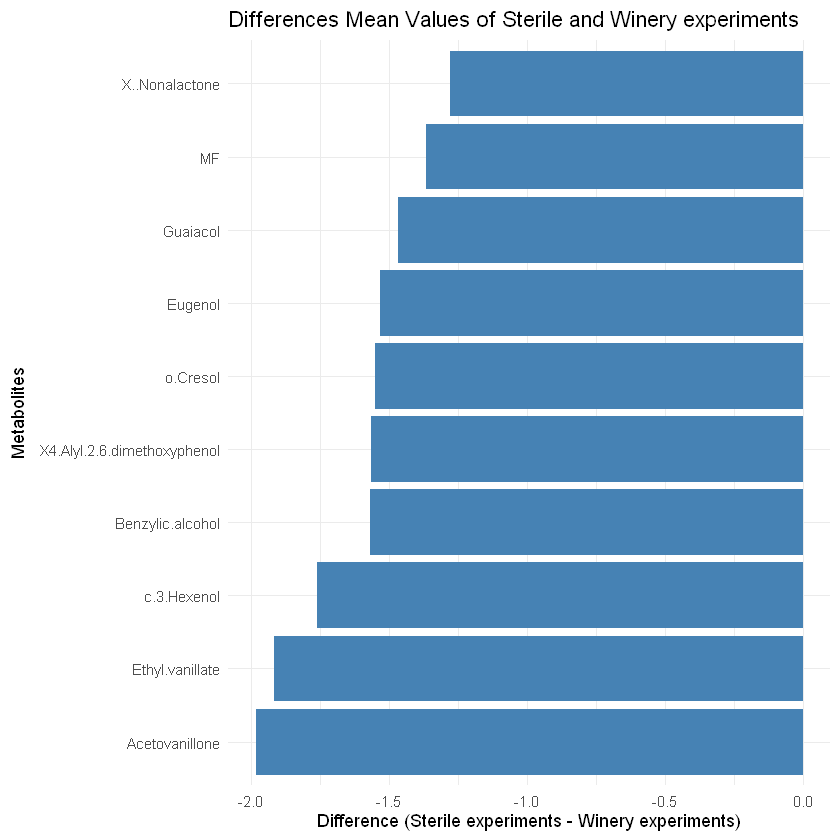

In [60]:
library(ggplot2)

# Create a bar plot for the differences without fill based on Difference > 0
ggplot(top_differences, aes(x = reorder(Column, Difference_vs_Winery), y = Difference_vs_Winery)) +
  geom_bar(stat = "identity", fill = "steelblue") +  # Use a single color for all bars
  coord_flip() +  # Flip coordinates for better readability
  labs(title = "Differences Mean Values of Sterile and Winery experiments",
       x = "Metabolites",
       y = "Difference (Sterile experiments - Winery experiments)") +
  theme_minimal()


In [61]:
rownames_DF1 <- c('01a', '01b', '01c', '02a', '02b', '02c', 
                  '04a', '04b', '04c', 
                  '05a', '05b', '05c')

rownames_DF2 <- c('wgt1', 'wgt2', 'wgt4', 'wgt5')



In [62]:
# Create DF1 by subsetting merged_df for the specified row names
DF11 <- merged_df[rownames(merged_df) %in% rownames_DF1, ]

# Create DF2 by subsetting merged_df for the specified row names
DF21 <- merged_df[rownames(merged_df) %in% rownames_DF2, ]

# Calculate column means for DF1 and DF2
mean_DF1 <- colMeans(DF11, na.rm = TRUE)
mean_DF2 <- colMeans(DF21, na.rm = TRUE)

# Align the means to ensure they have the same names
common_names <- intersect(names(mean_DF1), names(mean_DF2))

# Calculate the difference only for common columns
difference_aligned <- mean_DF1[common_names] - mean_DF2[common_names]

# Create a summary data frame
summary_df <- data.frame(
  Column = common_names,
  Mean_DF1 = mean_DF1[common_names],
  Mean_DF2 = mean_DF2[common_names],
  Difference_vs_Winery = difference_aligned
)

head(summary_df)

,Column,Mean_DF1,Mean_DF2,Difference_vs_Winery
,<chr>,<dbl>,<dbl>,<dbl>
Acetaldehyde,Acetaldehyde,0.4017429,-0.1866833,0.5884262
Diacetyl,Diacetyl,0.1195717,-0.2391434,0.3587150
Acetoine,Acetoine,-0.1367254,1.2931990,-1.4299244
Ethyl.acetate,Ethyl.acetate,-0.1909225,1.7711658,-1.9620883
Isoamyl.acetate,Isoamyl.acetate,-0.1172393,1.6918288,-1.8090681
Hexyl.acetate,Hexyl.acetate,0.2545480,1.5529637,-1.2984156


In [63]:
# Get the top 10 largest differences by absolute value
top_differences <- summary_df[order(abs(summary_df$Difference), decreasing = TRUE), ][1:10, ]

top_differences

,Column,Mean_DF1,Mean_DF2,Difference_vs_Winery
,<chr>,<dbl>,<dbl>,<dbl>
Butyric.acid,Butyric.acid,-0.1111405,2.028962,-2.140103
Ethyl.acetate,Ethyl.acetate,-0.1909225,1.771166,-1.962088
Acetovanillone,Acetovanillone,-0.4992492,1.432903,-1.932152
c.3.Hexenol,c.3.Hexenol,-0.1563527,1.678965,-1.835317
Isoamyl.acetate,Isoamyl.acetate,-0.1172393,1.691829,-1.809068
X4.Vinylguaiacol,X4.Vinylguaiacol,-0.1141287,1.685759,-1.799888
X..Citronelol,X..Citronelol,-0.3494225,1.377242,-1.726664
X4.Ethylguaiacol,X4.Ethylguaiacol,-0.2670559,1.341815,-1.608870
Ethyl.vanillate,Ethyl.vanillate,-0.5554421,1.018854,-1.574296


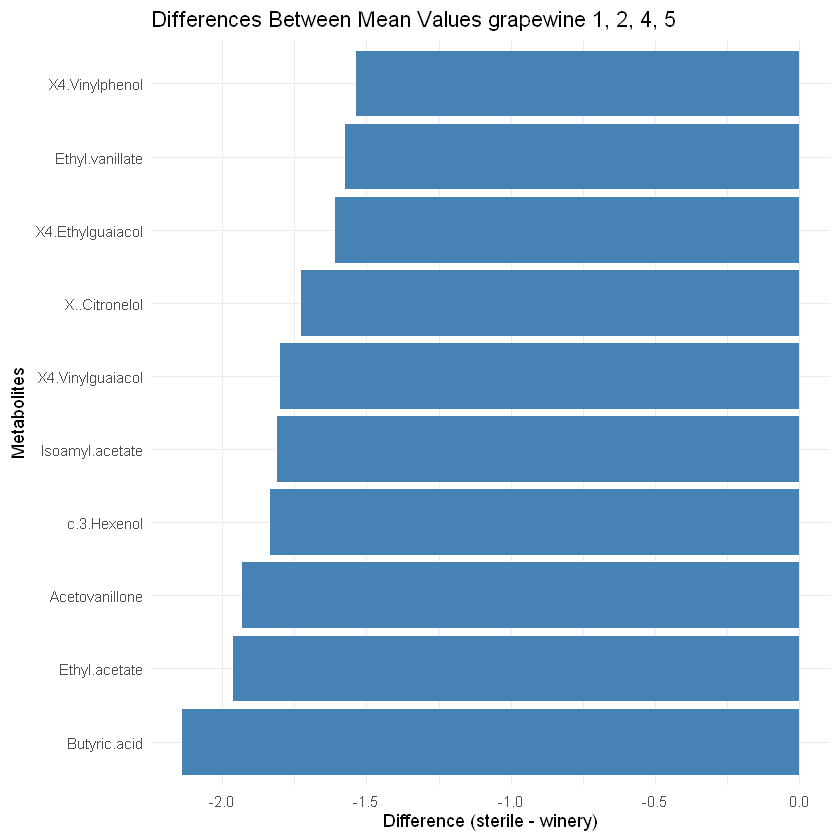

In [64]:
# Create a bar plot for the differences without fill based on Difference > 0
ggplot(top_differences, aes(x = reorder(Column, Difference_vs_Winery), y = Difference_vs_Winery)) +
  geom_bar(stat = "identity", fill = "steelblue") +  # Use a single color for all bars
  coord_flip() +  # Flip coordinates for better readability
  labs(title = "Differences Between Mean Values grapewine 1, 2, 4, 5",
       x = "Metabolites",
       y = "Difference (sterile - winery)") +
  theme_minimal()


In [65]:
merged_df %>%
  select("Butyric.acid", "Ethyl.acetate", "Acetovanillone", "c.3.Hexenol", "Isoamyl.acetate")





,Butyric.acid,Ethyl.acetate,Acetovanillone,c.3.Hexenol,Isoamyl.acetate
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01a,-0.41060266,-0.7148401,-0.57090713,-0.8618026,-0.82807250
01b,-0.37531882,-0.3002697,-0.36962216,-0.8618026,-0.65765013
01c,-0.82798424,-0.5904242,-0.85322485,-0.8618026,-0.81641244
02a,0.88459376,-0.2832349,-0.19631348,0.4054175,0.16717298
02b,0.99537858,-0.2462812,-0.43666302,0.1541393,0.53642994
02c,0.32015815,-2.5553590,-0.07079153,0.4388396,0.56801511
03a,0.63865603,0.9384916,-0.58579105,-0.8618026,1.29818768
03b,0.69732033,0.5713858,-0.66676738,-0.8618026,1.20359811
03c,0.32037076,0.6391426,-0.65166952,0.1923951,1.01312780


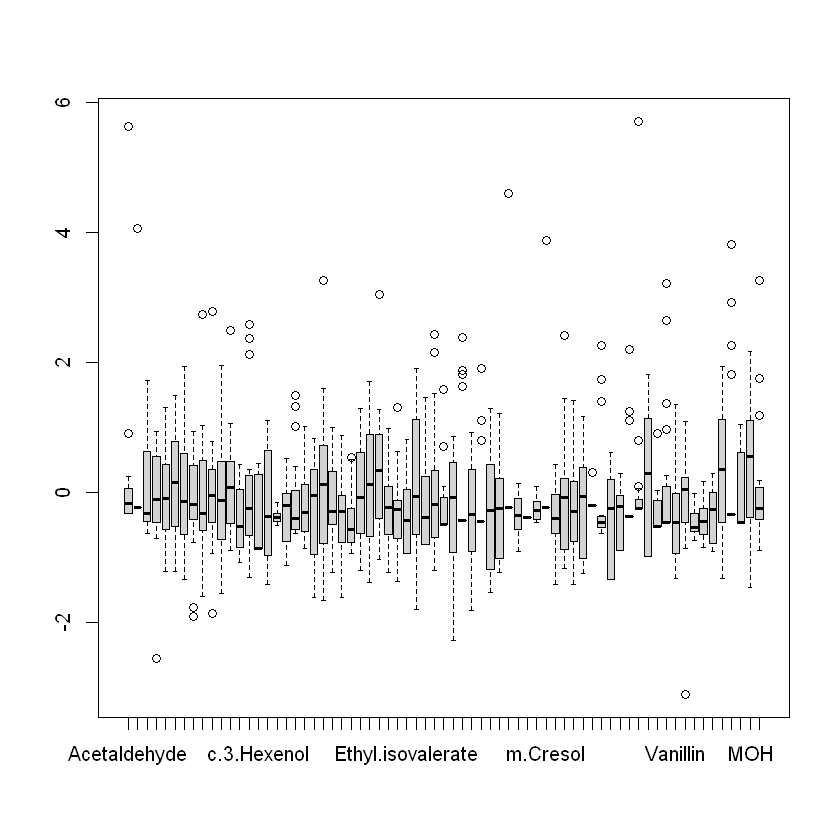

In [66]:
# merged_df
pattern_df1 <- "^0[1-7][abc]$"

dfbox = merged_df[grep(pattern_df1, rownames(merged_df)), ]
boxplot(dfbox, scale.default = TRUE)

In [67]:
dfbox %>%
  select("t.Whiskylactone", "Acetaldehyde", "MP", "Acetic.acid", "X..Decalactone", "X..Ionone", "X1.Hexanol", "MOH", "c.Whiskylactone", "Phenylethyl.acetate")

,t.Whiskylactone,Acetaldehyde,MP,Acetic.acid,X..Decalactone,X..Ionone,X1.Hexanol,MOH,c.Whiskylactone,Phenylethyl.acetate
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01a,-0.242077369,-0.004285321,3.8070788,-0.94138029,-0.45957705,-0.2368548,-0.1828128,1.51417843,-0.9861556,-0.28644598
01b,-0.242077369,-0.331546462,-0.3371279,0.02256218,1.36859845,-0.2368548,-0.5169965,-0.47407181,1.3871151,-0.29847335
01c,-0.242077369,-0.331546462,-0.3371279,0.05884189,0.96316459,-0.2368548,-0.3009198,-0.31686133,1.8098888,-0.63332372
02a,-0.242077369,-0.331546462,1.8089791,-1.57641176,-0.45957705,-0.2368548,0.2812872,0.74893328,-0.9861556,0.32015168
02b,-0.242077369,0.902760261,2.2530013,3.25309208,-0.45957705,-0.2368548,0.2460596,0.47843877,0.9650440,0.23051065
02c,0.087391858,0.238196442,2.9190345,-1.66869405,-0.45957705,-0.2368548,-0.2305217,0.62871350,-0.9861556,0.73771543
03a,0.004876182,0.021064026,-0.3371279,0.78834075,-0.45957705,-0.2368548,-0.8245804,-0.20357730,-0.9861556,0.22374549
03b,-0.242077369,0.065666647,-0.3371279,0.44934501,-0.45957705,4.6038850,-0.3915438,0.27036607,-0.9861556,0.29148295
03c,0.061184262,0.100834923,-0.3371279,0.65477035,-0.45957705,-0.2368548,-0.6432296,-1.22313353,-0.9861556,0.34307488


In [68]:
# Calculate the standard deviation for each variable
variations <- sapply(dfbox, sd, na.rm = TRUE)

# Sort the standard deviations in descending order
sorted_variations <- sort(variations, decreasing = TRUE)

# Select the top 10 variables with the most variation
top_10_variations <- head(sorted_variations, 10)

# Display the results
data.frame(top_10_variations)

,top_10_variations
,<dbl>
t.Whiskylactone,1.330909
Acetaldehyde,1.316581
MP,1.292218
Acetic.acid,1.159585
X..Decalactone,1.099545
X..Ionone,1.082422
X1.Hexanol,1.079955
MOH,1.078092
c.Whiskylactone,1.067137


# End of AI code

In [69]:
DF11 %>%
  select("MF", "X4.Vinylguaiacol", "X4.Vinylphenol", "Acetic.acid", "AMH")
DF21 %>%
  select("MF", "X4.Vinylguaiacol", "X4.Vinylphenol", "Acetic.acid", "AMH")

,MF,X4.Vinylguaiacol,X4.Vinylphenol,Acetic.acid,AMH
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01a,-0.78726206,-0.41138695,-0.4048722,-0.94138029,-0.47443516
01b,0.01221077,0.52767316,-0.3569086,0.02256218,1.04280586
01c,-0.22225236,0.04754132,-0.5124398,0.05884189,0.73842502
02a,-0.84667243,-0.23546191,-0.3696375,-1.57641176,-0.45705408
02b,-0.31906925,1.40913809,-0.4115752,3.25309208,-0.15606466
02c,-0.87356601,-0.31035967,-0.3716225,-1.66869405,-0.45832587
04a,0.04643897,-0.86368040,-0.4983558,1.60426617,0.01605041
04b,0.08140062,-0.66807073,-0.4096890,0.95241267,0.87662579
04c,0.18432969,-0.71709795,-0.5431400,1.00532361,-0.47443516


,MF,X4.Vinylguaiacol,X4.Vinylphenol,Acetic.acid,AMH
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
wgt1,-0.4765190,0.4879812,0.2625352,1.4931907,0.0232572
wgt2,-0.3202917,2.7258659,0.2411119,0.3559395,-0.4744352
wgt4,-0.1215237,2.2818373,2.8918608,1.2482432,-0.4744352
wgt5,-0.7589016,1.2473510,3.2557998,0.3924302,-0.3400497


In [70]:
# linkage methods to test
m <- c( "average", "single", "complete", "ward")
names(m) <- c( "average", "single", "complete", "ward")

# function to compute agglomerative coefficient
ac <- function(x) {
    agnes(merged_scaled_df, method = x)$ac
}   

# calculate agglomerative coefficient for each clustering linkage method
sapply(m, ac)

average    single  complete      ward 
0.5334873 0.4398390 0.6022494 0.7191500

Ward gives the highest agglomerative coefficient of the cluster methods...

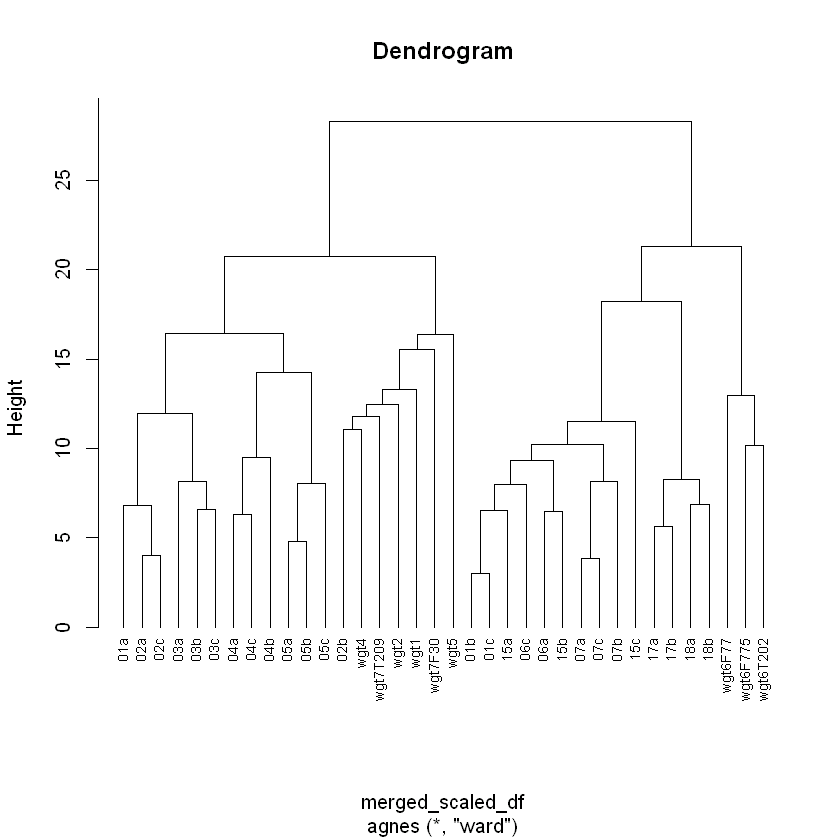

In [71]:
# perform hierarchical clustering using Ward's because highest coefficient
clust <- agnes(merged_scaled_df, method = "ward")

# produce dendrogram
pltree(clust, cex = 0.7, hang = -1, main = "Dendrogram") 

# PCA clustering

 [1] 21.96 15.28  8.61  7.83  5.35  4.76  4.15  3.97  3.05  2.96  2.57  2.40
[13]  2.20  1.95  1.78  1.58  1.39  1.14  1.03  0.94  0.83  0.69  0.62  0.50
[25]  0.48  0.42  0.33  0.31  0.23  0.22  0.15  0.11  0.07  0.07  0.05  0.00


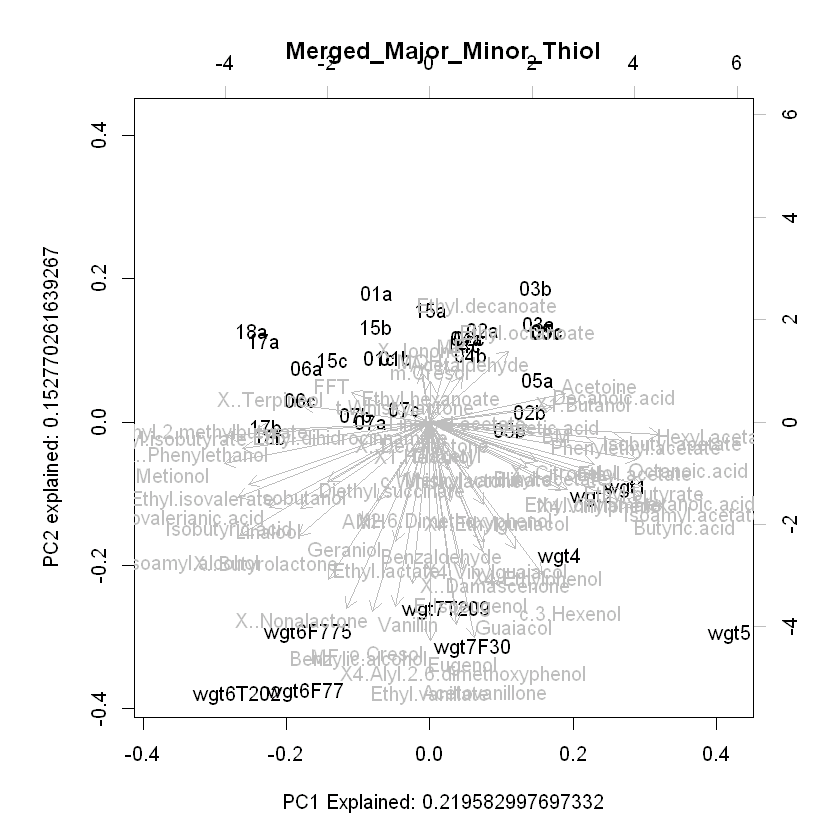

In [72]:
metabolomics <- prcomp(na.omit(merged_df), scale=FALSE)
# df_wineries_pca$rotation <- -1*df_wineries_pca$rotation
# head(df_wineries_pca$rotation)
stdeviations_metabolomics <- metabolomics$sdev^2 / sum(metabolomics$sdev^2)
# stdeviations_metabolomics

biplot(metabolomics, col = c("black", "gray"), 
       xlab = paste("PC1 Explained:", stdeviations_metabolomics[1]),
       ylab = paste("PC2 explained:", stdeviations_metabolomics[2]))
title("Merged_Major_Minor_Thiol")

# Variance of each PC
var_pcs <- metabolomics$sdev^2

# Percentage of variance explained by each PC
var_explained_percent <- round(var_pcs / sum(var_pcs) * 100, 2)

# Print percentages
print(var_explained_percent)

In [73]:
# library(dplyr)
# Didnt work. Don't use most of it anyway. Meh.

# majors_ <- majors_ %>%
#     mutate_if(is.numeric, scale)
# minors_ <- minors_ %>%
#     mutate_if(is.numeric, scale)
# thiols_ <- thiols_ %>%
#     mutate_if(is.numeric, scale)

Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"


Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"
Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"
Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"
Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"


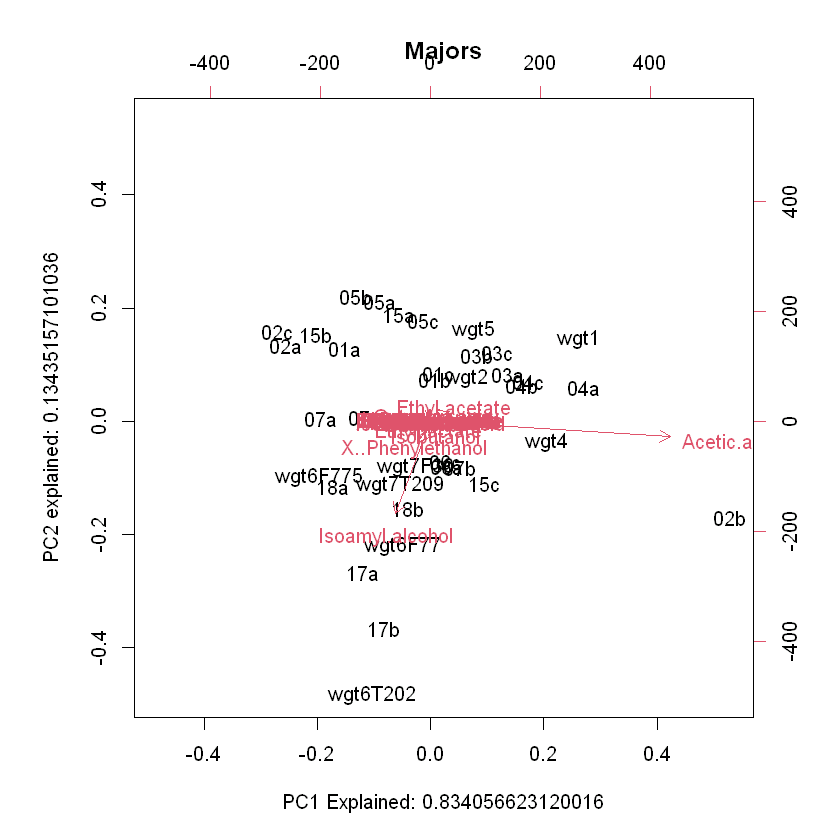

Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"
Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"
Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"
Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"
Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"
Warning message in arrows(0, 0, y[, 1L] * 0.8, y[, 2L] * 0.8, col = col[2L], length = arrow.len):
"zero-length arrow is of indeterminate angle and so skipped"
Warning message in arrows(0, 0, y[, 1L] * 0.8,

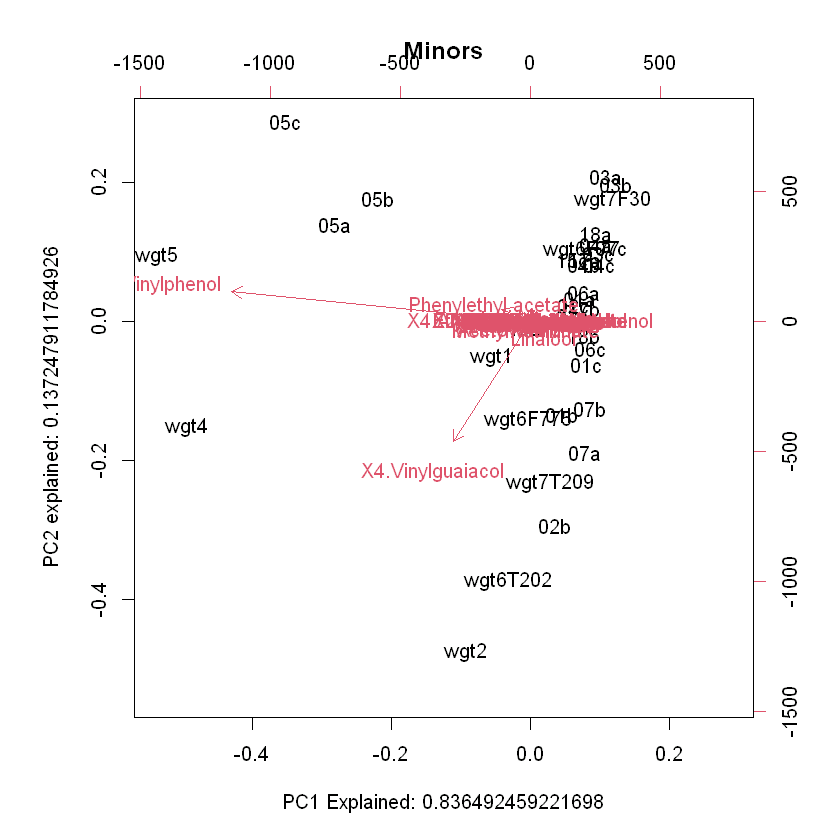

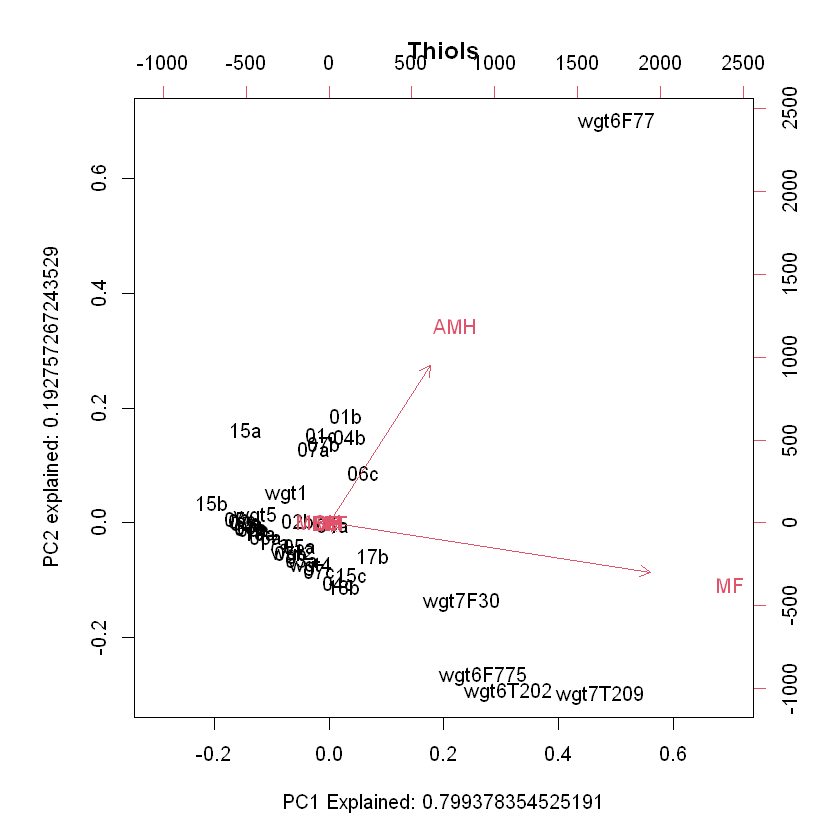

: 

In [ ]:


metabolomics <- prcomp(na.omit(data.frame(majors_[, -1], row.names = majors_[, 1])), scale=FALSE)
stdeviations_metabolomics <- metabolomics$sdev^2 / sum(metabolomics$sdev^2)

biplot(metabolomics, xlab = paste("PC1 Explained:", stdeviations_metabolomics[1]),
       ylab = paste("PC2 explained:", stdeviations_metabolomics[2]))
title("Majors")
metabolomics <- prcomp(na.omit(data.frame(minors_[, -1], row.names = minors_[, 1])), scale=FALSE)
stdeviations_metabolomics <- metabolomics$sdev^2 / sum(metabolomics$sdev^2)

biplot(metabolomics, xlab = paste("PC1 Explained:", stdeviations_metabolomics[1]),
       ylab = paste("PC2 explained:", stdeviations_metabolomics[2]))
title("Minors")

metabolomics <- prcomp(na.omit(data.frame(thiols_[, -1], row.names = thiols_[, 1])), scale=FALSE)
stdeviations_metabolomics <- metabolomics$sdev^2 / sum(metabolomics$sdev^2)

biplot(metabolomics, xlab = paste("PC1 Explained:", stdeviations_metabolomics[1]),
       ylab = paste("PC2 explained:", stdeviations_metabolomics[2]))
title("Thiols")